## Lab 2
### Part 2: Dealing with overfitting

Today we work with [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) (*hint: it is available in `torchvision`*).

Your goal for today:
1. Train a FC (fully-connected) network that achieves >= 0.885 test accuracy.
2. Cause considerable overfitting by modifying the network (e.g. increasing the number of network parameters and/or layers) and demonstrate in in the appropriate way (e.g. plot loss and accurasy on train and validation set w.r.t. network complexity).
3. Try to deal with overfitting (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results.

__Please, write a small report describing your ideas, tries and achieved results in the end of this file.__

*Note*: Tasks 2 and 3 are interrelated, in task 3 your goal is to make the network from task 2 less prone to overfitting. Task 1 is independent from 2 and 3.

*Note 2*: We recomment to use Google Colab or other machine with GPU acceleration.

In [1]:
from pathlib import Path
from copy import deepcopy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print('Устройство:', device, '| PyTorch:', torch.__version__)

def loader(x, y, batch_size=256, shuffle=False, seed=SEED):
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)

@torch.no_grad()
def evaluate(model, batches):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in batches:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += nn.functional.cross_entropy(logits, y, reduction='sum').item()
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)
    return {'loss': total_loss / count, 'accuracy': correct / count}

def fit(model, train_batches, train_eval_batches, val_batches, epochs, lr=1e-3,
        weight_decay=0.0, select_best=True):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=lr * 0.05)
    history, best_state, best_loss, best_epoch = [], None, float('inf'), 0
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_batches:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
        tr, va = evaluate(model, train_eval_batches), evaluate(model, val_batches)
        history.append({'epoch': epoch, 'train_loss': tr['loss'], 'val_loss': va['loss'],
                        'train_accuracy': tr['accuracy'], 'val_accuracy': va['accuracy']})
        if va['loss'] < best_loss:
            best_loss, best_epoch = va['loss'], epoch
            best_state = deepcopy(model.state_dict())
        scheduler.step()
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"Эпоха {epoch:3d}: train acc={tr['accuracy']:.4f}, val acc={va['accuracy']:.4f}, "
                  f"train loss={tr['loss']:.4f}, val loss={va['loss']:.4f}", flush=True)
    if select_best:
        model.load_state_dict(best_state)
    return pd.DataFrame(history), best_epoch

def plot_histories(histories, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, history in histories.items():
        for ax, metric in zip(axes, ['loss', 'accuracy']):
            line, = ax.plot(history.epoch, history['train_' + metric], label=name + ': train')
            ax.plot(history.epoch, history['val_' + metric], '--', color=line.get_color(),
                    label=name + ': validation')
            ax.set(xlabel='Эпоха', ylabel=metric)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Устройство: cpu | PyTorch: 2.15.0+cpu


In [2]:
import gzip
from urllib.request import urlretrieve

DATA = Path('data/fashion')
DATA.mkdir(parents=True, exist_ok=True)
base_url = 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'

def read_fashion(prefix):
    arrays = []
    for suffix, offset in [('images-idx3-ubyte.gz', 16), ('labels-idx1-ubyte.gz', 8)]:
        name = prefix + '-' + suffix
        path = DATA / name
        if not path.exists():
            urlretrieve(base_url + name, path)
        with gzip.open(path, 'rb') as stream:
            arrays.append(np.frombuffer(stream.read(), dtype=np.uint8, offset=offset).copy())
    x = torch.from_numpy(arrays[0].reshape(-1, 1, 28, 28)).float() / 255
    y = torch.from_numpy(arrays[1]).long()
    return x, y

In [3]:
from sklearn.model_selection import train_test_split

x_all, y_all = read_fashion('train')
x_test, y_test = read_fashion('t10k')
train_idx, val_idx = train_test_split(np.arange(len(y_all)), test_size=10000,
                                    stratify=y_all.numpy(), random_state=SEED)
# mean и std считаются только по train
mean, std = x_all[train_idx].mean(), x_all[train_idx].std()
x_train = (x_all[train_idx] - mean) / std
x_val = (x_all[val_idx] - mean) / std
x_test = (x_test - mean) / std
y_train, y_val = y_all[train_idx], y_all[val_idx]
print('Train / validation / test:', len(y_train), len(y_val), len(y_test))

Train / validation / test: 50000 10000 10000


In [4]:
train_loader = loader(x_train, y_train, shuffle=True)
train_eval_loader = loader(x_train, y_train, batch_size=1024)
val_loader = loader(x_val, y_val, batch_size=1024)
test_loader = loader(x_test, y_test, batch_size=1024)

In [5]:
print('Число тестовых изображений:', len(y_test))

Число тестовых изображений: 10000


In [6]:
images, labels = next(iter(train_loader))
print('Форма батча:', images.shape, '| форма меток:', labels.shape)

Форма батча: torch.Size([256, 1, 28, 28]) | форма меток: torch.Size([256])


### Task 1
Train a network that achieves $\geq 0.885$ test accuracy. It's fine to use only Linear (`nn.Linear`) layers and activations/dropout/batchnorm. Convolutional layers might be a great use, but we will meet them a bit later.

In [7]:
class TinyNeuralNetwork(nn.Module):
    def __init__(self, input_shape=784, num_classes=10, input_channels=1):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(), nn.Linear(input_shape, 512), nn.BatchNorm1d(512),
            nn.ReLU(), nn.Dropout(0.2), nn.Linear(512, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, num_classes))

    def forward(self, inp):
        return self.model(inp)

In [8]:
print(TinyNeuralNetwork())
print('Параметров:', sum(p.numel() for p in TinyNeuralNetwork().parameters()))

TinyNeuralNetwork(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=512, out_features=256, bias=True)
    (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=256, out_features=10, bias=True)
  )
)
Параметров: 537354


Данные делятся на train 50 000, validation 10 000 и test 10 000. По validation выбирается эпоха с минимальной cross-entropy, test используется один раз в конце. В сети только полносвязные слои, BatchNorm, ReLU и Dropout. Метрики на train считаются в режиме eval, чтобы их можно было сравнивать с validation.

Эпоха   1: train acc=0.8454, val acc=0.8459, train loss=0.4272, val loss=0.4220


Эпоха   5: train acc=0.9143, val acc=0.8946, train loss=0.2327, val loss=0.2909


Эпоха  10: train acc=0.9340, val acc=0.9009, train loss=0.1758, val loss=0.2809


Эпоха  15: train acc=0.9547, val acc=0.9068, train loss=0.1229, val loss=0.2758


Эпоха  20: train acc=0.9738, val acc=0.9100, train loss=0.0771, val loss=0.2841


Эпоха  25: train acc=0.9853, val acc=0.9129, train loss=0.0491, val loss=0.2910


Эпоха  30: train acc=0.9895, val acc=0.9134, train loss=0.0386, val loss=0.3009


Выбранная эпоха: 11
Test: {'loss': 0.30467451934814455, 'accuracy': 0.8935}


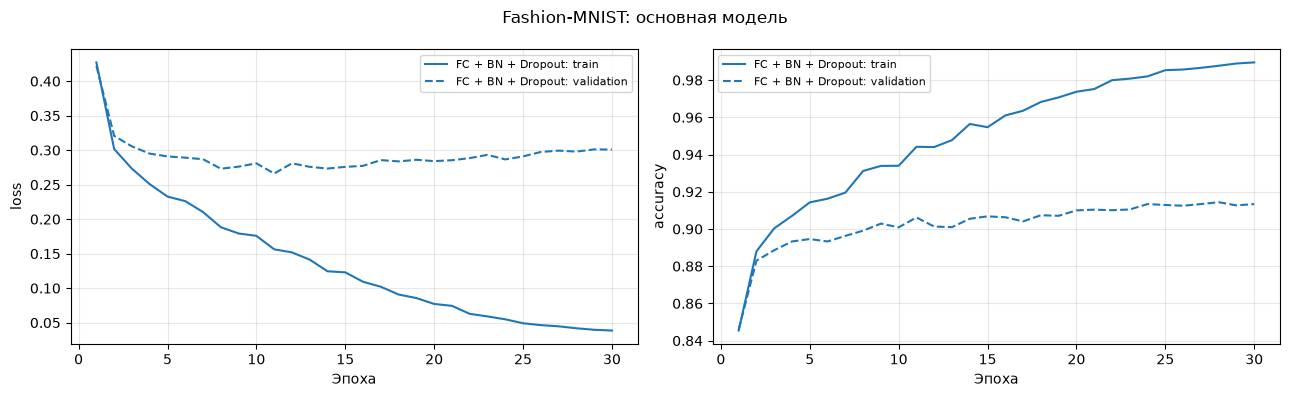

In [9]:
set_seed()
model = TinyNeuralNetwork().to(device)
baseline_history, baseline_epoch = fit(
    model, train_loader, train_eval_loader, val_loader, epochs=30, weight_decay=1e-4)
baseline_test = evaluate(model, test_loader)
print('Выбранная эпоха:', baseline_epoch)
print('Test:', baseline_test)
assert baseline_test['accuracy'] >= 0.885
plot_histories({'FC + BN + Dropout': baseline_history}, 'Fashion-MNIST: основная модель')

### Task 2: Overfit it.
Build a network that will overfit to this dataset. Demonstrate the overfitting in the appropriate way (e.g. plot loss and accurasy on train and test set w.r.t. network complexity).

*Note:* you also might decrease the size of `train` dataset to enforce the overfitting and speed up the computations.

In [10]:
class OverfittingNeuralNetwork(nn.Module):
    def __init__(self, input_shape=784, num_classes=10, input_channels=1):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(), nn.Linear(input_shape, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, num_classes))

    def forward(self, inp):
        return self.model(inp)

In [11]:
print(OverfittingNeuralNetwork())
print('Параметров:', sum(p.numel() for p in OverfittingNeuralNetwork().parameters()))

OverfittingNeuralNetwork(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=10, bias=True)
  )
)
Параметров: 798474


Эпоха   1: train acc=0.6660, val acc=0.6593, train loss=0.8514, val loss=0.8505


Эпоха   5: train acc=0.8730, val acc=0.8185, train loss=0.3558, val loss=0.4923


Эпоха  10: train acc=0.9130, val acc=0.8174, train loss=0.2400, val loss=0.5150


Эпоха  15: train acc=0.9730, val acc=0.8322, train loss=0.0855, val loss=0.5836


Эпоха  20: train acc=0.9850, val acc=0.8356, train loss=0.0486, val loss=0.6758


Эпоха  25: train acc=0.9900, val acc=0.8415, train loss=0.0313, val loss=0.7181


... (4 outputs left out)

Эпоха  50: train acc=1.0000, val acc=0.8418, train loss=0.0008, val loss=0.9796


Эпоха  55: train acc=1.0000, val acc=0.8422, train loss=0.0007, val loss=0.9883


Эпоха  60: train acc=1.0000, val acc=0.8421, train loss=0.0007, val loss=0.9943


Эпоха  65: train acc=1.0000, val acc=0.8417, train loss=0.0007, val loss=0.9979


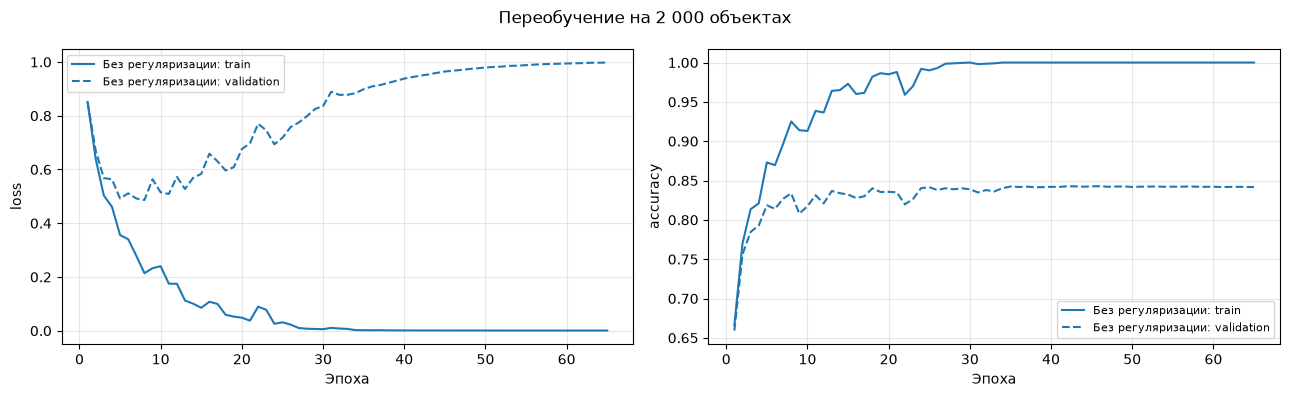

In [12]:
# берутся только 2000 картинок из train, на маленькой выборке сеть переобучается быстрее
small_idx, _ = train_test_split(np.arange(len(y_train)), train_size=2000,
                                stratify=y_train.numpy(), random_state=SEED)
small_x, small_y = x_train[small_idx], y_train[small_idx]
small_eval = loader(small_x, small_y, batch_size=1024)
set_seed()
overfit_model = OverfittingNeuralNetwork().to(device)
overfit_history, _ = fit(overfit_model, loader(small_x, small_y, shuffle=True, batch_size=128),
                           small_eval, val_loader, epochs=65, select_best=False)
plot_histories({'Без регуляризации': overfit_history}, 'Переобучение на 2 000 объектах')

### Task 3: Fix it.
Fix the overfitted network from the previous step (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results. 

In [13]:
class FixedNeuralNetwork(nn.Module):
    def __init__(self, input_shape=784, num_classes=10, input_channels=1):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(), nn.Linear(input_shape, 512), nn.BatchNorm1d(512),
            nn.ReLU(), nn.Dropout(0.4), nn.Linear(512, 512), nn.BatchNorm1d(512),
            nn.ReLU(), nn.Dropout(0.4), nn.Linear(512, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, inp):
        return self.model(inp)

In [14]:
print(FixedNeuralNetwork())
print('Параметров:', sum(p.numel() for p in FixedNeuralNetwork().parameters()))

FixedNeuralNetwork(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.4, inplace=False)
    (5): Linear(in_features=512, out_features=512, bias=True)
    (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.4, inplace=False)
    (9): Linear(in_features=512, out_features=256, bias=True)
    (10): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Dropout(p=0.3, inplace=False)
    (13): Linear(in_features=256, out_features=10, bias=True)
  )
)
Параметров: 801034


Эпоха   1: train acc=0.7405, val acc=0.7284, train loss=0.8370, val loss=0.8592


Эпоха   5: train acc=0.8945, val acc=0.8284, train loss=0.3157, val loss=0.4880


Эпоха  10: train acc=0.9365, val acc=0.8299, train loss=0.1846, val loss=0.4930


Эпоха  15: train acc=0.9530, val acc=0.8264, train loss=0.1281, val loss=0.5580


Эпоха  20: train acc=0.9785, val acc=0.8258, train loss=0.0713, val loss=0.5862


Эпоха  25: train acc=0.9885, val acc=0.8348, train loss=0.0379, val loss=0.6148


... (4 outputs left out)

Эпоха  50: train acc=1.0000, val acc=0.8430, train loss=0.0022, val loss=0.6985


Эпоха  55: train acc=1.0000, val acc=0.8446, train loss=0.0015, val loss=0.7071


Эпоха  60: train acc=1.0000, val acc=0.8467, train loss=0.0011, val loss=0.7163


Эпоха  65: train acc=1.0000, val acc=0.8461, train loss=0.0010, val loss=0.7162


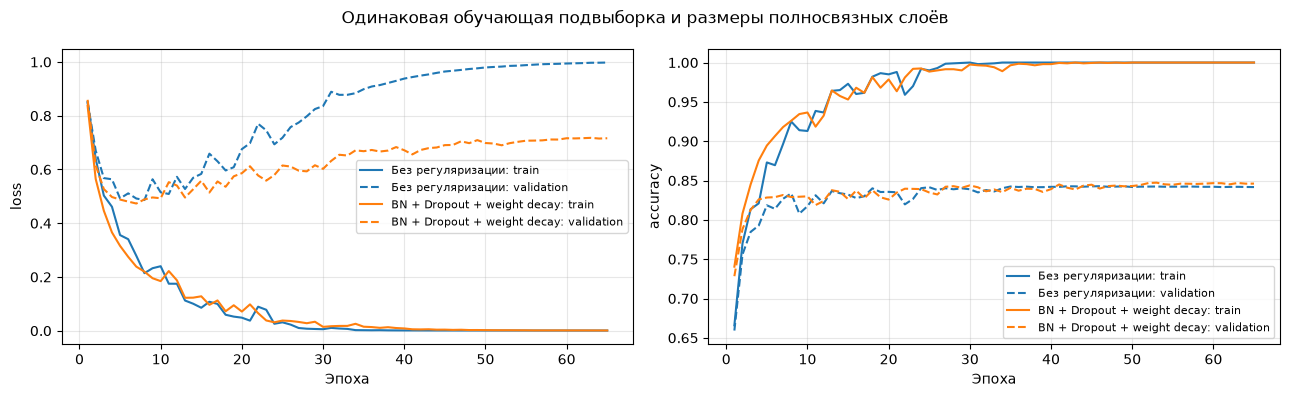

,model,epoch,train_loss,val_loss,train_accuracy,val_accuracy,accuracy_gap
0,Без регуляризации,65.0,0.00069,0.99789,1.0,0.8417,0.1583
1,С регуляризацией,65.0,0.00095,0.71623,1.0,0.8461,0.1539


In [15]:
# всё как в Task 2, добавлены только BatchNorm, Dropout и weight decay
set_seed()
fixed_model = FixedNeuralNetwork().to(device)
fixed_history, _ = fit(
    fixed_model, loader(small_x, small_y, shuffle=True, batch_size=128), small_eval,
    val_loader, epochs=65, weight_decay=1e-3, select_best=False)
plot_histories({'Без регуляризации': overfit_history, 'BN + Dropout + weight decay': fixed_history},
               'Одинаковая обучающая подвыборка и размеры полносвязных слоёв')
comparison = pd.DataFrame([
    {'model': name, **hist.iloc[-1].to_dict(),
     'accuracy_gap': hist.iloc[-1].train_accuracy - hist.iloc[-1].val_accuracy}
    for name, hist in [('Без регуляризации', overfit_history), ('С регуляризацией', fixed_history)]])
display(comparison.round(5))

### Выводы

Сеть 784-512-256-10 с ReLU, BatchNorm и Dropout обучалась 30 эпох с AdamW. По минимуму validation cross-entropy выбрана 11-я эпоха. Accuracy на тесте 0.8935, это выше нужных 0.885.

Для переобучения взята сеть 784-512-512-256-10 без регуляризации и только 2 000 картинок для обучения. К 65-й эпохе train accuracy равна 1.0, а validation accuracy 0.842. Лосс на train продолжает падать, а на validation растёт, то есть сеть запомнила обучающие картинки.

В той же сети добавлены BatchNorm, Dropout и weight decay, данные и число эпох те же. Validation accuracy выросла немного, до 0.846, а validation loss упал с 0.998 до 0.716. Train accuracy всё равно 1.0, так что переобучение уменьшилось, но не исчезло. Какой из трёх методов помог больше, здесь отдельно не проверялось.